# Семинар 11. Последовательные рекомендации: SASRec

Готовим истории пользователей MovieLens 1M, обучаем SASRec и сравниваем функции потерь при одинаковом выборе негативов. Основной маршрут содержит семь конфигураций и Global TopPop. Остальные сочетания loss и sampler, исправленный LogQ и дополнительные метрики вынесены в бонус.

In [1]:
import importlib.util
import subprocess
import sys

requirements = {"numpy": "numpy>=2.2,<3", "torch": "torch>=2.6,<3"}
missing = [spec for module, spec in requirements.items() if importlib.util.find_spec(module) is None]
if missing:
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])

## 1. Настройки

В `demo` каждая эпоха ограничена 30 батчами, максимум - пять эпох. Это короткий запуск для сравнения поведения функций потерь. Режим `full` снимает ограничение числа батчей и увеличивает предел эпох; при его выборе выполните ноутбук заново.

Реальные фильмы имеют ID `1..N`, `PAD` - ID `N+1`; ID `0` не используется. Автоматически выбирается CUDA, если она доступна, иначе CPU. На разных устройствах результаты могут различаться.

In [24]:
import os
import csv
import json
import math
import random
import time
import hashlib
import urllib.request
import zipfile
from pathlib import Path
from collections import defaultdict
from datetime import datetime, timezone

import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.data import Dataset, DataLoader

MODE = os.environ.get("SASREC_MODE", "full")  # demo, full или smoke (техническая проверка)
PRESETS = {
    "demo": dict(max_len=50, dim=64, batch_size=32, n_neg=32,
                 max_epochs=5, max_batches=30, patience=2),
    "full": dict(max_len=100, dim=64, batch_size=64, n_neg=128,
                 max_epochs=100, max_batches=None, patience=5),
    "smoke": dict(max_len=20, dim=16, batch_size=16, n_neg=8,
                  max_epochs=2, max_batches=2, patience=1),
}
CFG = dict(PRESETS[MODE], n_heads=1, n_layers=2, dropout=0.2,
           learning_rate=1e-3, gbce_t=0.75, min_delta=1e-4,
           eval_batch_size=128, min_count=20)
SEEDS = [42]  # Для оценки разброса можно указать несколько seed.
KS = (5, 10, 20)
DEVICE = torch.device(os.environ.get("SASREC_DEVICE", "cuda" if torch.cuda.is_available() else "cpu"))
torch.set_num_threads(2)
DATA_DIR = Path(os.environ.get("SASREC_DATA_DIR", "data"))
OUTPUT_DIR = Path(os.environ.get("SASREC_OUTPUT_DIR", "artifacts")) / "train_only" / "shared_item_embeddings" / MODE
DATA_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

def seed_everything(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True
        torch.backends.cudnn.benchmark = False

seed_everything(SEEDS[0])
print("Mode:", MODE, "Device:", DEVICE)
print("NumPy:", np.__version__, "PyTorch:", torch.__version__)
print(CFG)

Mode: full Device: cpu
NumPy: 2.5.4 PyTorch: 2.15.0+cu132
{'max_len': 100, 'dim': 64, 'batch_size': 64, 'n_neg': 128, 'max_epochs': 100, 'max_batches': None, 'patience': 5, 'n_heads': 1, 'n_layers': 2, 'dropout': 0.2, 'learning_rate': 0.001, 'gbce_t': 0.75, 'min_delta': 0.0001, 'eval_batch_size': 128, 'min_count': 20}


## 2. MovieLens 1M

Каждую оценку фильма, включая низкую, считаем событием взаимодействия. Предсказываем следующий оцененный фильм; это не задача предсказания того, понравится ли он пользователю. Timestamp хранит время выставления оценки.

В `ratings.dat` строки имеют вид `user_id::movie_id::rating::timestamp`. Названия и жанры берем из `movies.dat`. Используем полный исходный архив, проверяем его MD5 и читаем данные без распаковки.

In [25]:
MOVIELENS_URL = "https://files.grouplens.org/datasets/movielens/ml-1m.zip"
MOVIELENS_MD5 = "c4d9eecfca2ab87c1945afe126590906"
archive_path = DATA_DIR / "ml-1m.zip"

if not archive_path.exists():
    temporary_path = archive_path.with_suffix(".download")
    with urllib.request.urlopen(MOVIELENS_URL, timeout=120) as response:
        with temporary_path.open("wb") as output:
            while chunk := response.read(1024 * 1024):
                output.write(chunk)
    temporary_path.replace(archive_path)

actual_md5 = hashlib.md5(archive_path.read_bytes()).hexdigest()
if actual_md5 != MOVIELENS_MD5:
    raise ValueError("Архив поврежден: удалите data/ml-1m.zip и повторите загрузку")

# Читаем только нужные файлы из архива, без распаковки на диск.
with zipfile.ZipFile(archive_path) as archive:
    rows = []
    for line in archive.read("ml-1m/ratings.dat").decode("latin-1").splitlines():
        user, item, rating, timestamp = map(int, line.split("::"))
        rows.append((user, item, rating, timestamp))
    raw = np.asarray(rows, dtype=np.int64)
    del rows
    movie_metadata = {}
    for line in archive.read("ml-1m/movies.dat").decode("latin-1").splitlines():
        item, title, genres = line.split("::")
        movie_metadata[int(item)] = {"title": title, "genres": set(genres.split("|"))}

# Столбцы массива raw: user, item, rating, timestamp.
# Равные timestamp упорядочиваем по исходному порядку строк (детерминированное соглашение).
raw = raw[np.argsort(raw[:, 3], kind="stable")]
print("Размер:", raw.shape, "MD5:", actual_md5)
print("Первые строки:\n", raw[:5])

Размер: (1000209, 4) MD5: c4d9eecfca2ab87c1945afe126590906
Первые строки:
 [[     6040       858         4 956703932]
 [     6040       593         5 956703954]
 [     6040      2384         4 956703954]
 [     6040      1961         4 956703977]
 [     6040      2019         5 956703977]]


In [26]:
def describe_interactions(rows, title):
    if len(rows) == 0:
        print(title, "- пустой набор")
        return
    users, user_counts = np.unique(rows[:, 0], return_counts=True)
    items, item_counts = np.unique(rows[:, 1], return_counts=True)
    density = len(rows) / (len(users) * len(items))
    dates = [datetime.fromtimestamp(int(t), timezone.utc).isoformat() for t in (rows[:, 3].min(), rows[:, 3].max())]
    print(f"\n{title}: events={len(rows):,}; users={len(users):,}; items={len(items):,}")
    print(f"Плотность={density:.4%}; разреженность={1-density:.4%}; время={dates}")
    def format_quantiles(values):
        quantiles = np.quantile(values, [0, .5, .9, 1])
        labels = ("min", "медиана", "p90", "max")
        def readable(value):
            number = f"{value:,.1f}" if value != int(value) else f"{int(value):,}"
            return number.replace(",", " ")
        return "; ".join(f"{label}={readable(value)}" for label, value in zip(labels, quantiles))

    print("Длина истории:", format_quantiles(user_counts))
    print("Частота фильма:", format_quantiles(item_counts))
    print("Оценки:", dict(zip(*np.unique(rows[:, 2], return_counts=True))))

describe_interactions(raw, "Исходный MovieLens")
assert len(np.unique(raw[:, :2], axis=0)) == len(raw), "Для этого семинара ожидаем уникальные user-item пары"


Исходный MovieLens: events=1,000,209; users=6,040; items=3,706
Плотность=4.4684%; разреженность=95.5316%; время=['2000-04-25T23:05:32+00:00', '2003-02-28T17:49:50+00:00']
Длина истории: min=20; медиана=96; p90=400; max=2 314
Частота фильма: min=1; медиана=123.5; p90=729.5; max=3 428
Оценки: {np.int64(1): np.int64(56174), np.int64(2): np.int64(107557), np.int64(3): np.int64(261197), np.int64(4): np.int64(348971), np.int64(5): np.int64(226310)}


## 3. Временное разбиение и 20-core

Границы общие для всех пользователей: примерно 80% событий в train, следующие 10% в val,
последние 10% в test. Одинаковые timestamp не разрываем между частями.
Это отличается от leave-last-two-out, где train одного пользователя может попасть в будущее другого.

**Порядок нужен для отсутствия утечки:** сначала определяем временные границы, затем считаем 20-core
только по прошлому (train). По очереди удаляем фильмы с частотой <20 и пользователей с историей <20,
пока набор перестанет меняться. Один проход не гарантирует оба ограничения одновременно.
Фильтрация по всему датасету заранее использовала бы будущую популярность.

На val и test оставляем пользователей и фильмы из полученного train. Поэтому удаляются и холодные
пользователи, и фильмы без обученного embedding. Весь эксперимент оценивает **фиксированную теплую когорту**;
пользователи, впервые появившиеся в val, не возвращаются в test. Число удалений выводим явно.

In [27]:
def iterative_core(rows, min_count=20):
    result = rows.copy()
    iteration = 0
    while len(result):
        previous_size = len(result)
        item_ids, counts = np.unique(result[:, 1], return_counts=True)
        result = result[np.isin(result[:, 1], item_ids[counts >= min_count])]
        user_ids, counts = np.unique(result[:, 0], return_counts=True)
        result = result[np.isin(result[:, 0], user_ids[counts >= min_count])]
        iteration += 1
        print(f"20-core, проход {iteration}: {len(result):,} событий")
        if len(result) == previous_size:
            break
    if not len(result):
        raise ValueError("После фильтрации нет данных")
    return result

val_start = int(raw[int(len(raw) * 0.8), 3])
test_start = int(raw[int(len(raw) * 0.9), 3])
train_raw = raw[raw[:, 3] < val_start]
val_raw = raw[(raw[:, 3] >= val_start) & (raw[:, 3] < test_start)]
test_raw = raw[raw[:, 3] >= test_start]
train = iterative_core(train_raw, CFG["min_count"])
warm_users = np.unique(train[:, 0])
warm_items = np.unique(train[:, 1])

def keep_warm(rows, name):
    user_ok = np.isin(rows[:, 0], warm_users)
    item_ok = np.isin(rows[:, 1], warm_items)
    print(f"{name}: холодных/отфильтрованных пользователей={len(np.unique(rows[~user_ok, 0]))}; "
          f"их событий={(~user_ok).sum():,}; событий с неизвестным фильмом среди теплых пользователей={(user_ok & ~item_ok).sum():,}")
    return rows[user_ok & item_ok].copy()

val = keep_warm(val_raw, "val")
test = keep_warm(test_raw, "test")
assert len(val) and len(test)
assert train[:, 3].max() < val[:, 3].min() <= val[:, 3].max() < test[:, 3].min()
for column in (0, 1):
    assert np.unique(train[:, column], return_counts=True)[1].min() >= CFG["min_count"]
for rows in (train, val, test):
    describe_interactions(rows, "train" if rows is train else "val" if rows is val else "test")

20-core, проход 1: 793,071 событий
20-core, проход 2: 793,052 событий
20-core, проход 3: 793,052 событий
val: холодных/отфильтрованных пользователей=642; их событий=78,904; событий с неизвестным фильмом среди теплых пользователей=338
test: холодных/отфильтрованных пользователей=285; их событий=27,469; событий с неизвестным фильмом среди теплых пользователей=1,423

train: events=793,052; users=5,275; items=2,896
Плотность=5.1914%; разреженность=94.8086%; время=['2000-04-25T23:05:32+00:00', '2000-12-02T14:51:59+00:00']
Длина истории: min=20; медиана=89; p90=353.6; max=1 774
Частота фильма: min=20; медиана=153; p90=669; max=2 886
Оценки: {np.int64(1): np.int64(44374), np.int64(2): np.int64(83511), np.int64(3): np.int64(205347), np.int64(4): np.int64(276289), np.int64(5): np.int64(183531)}

val: events=20,782; users=492; items=2,702
Плотность=1.5633%; разреженность=98.4367%; время=['2000-12-02T14:52:18+00:00', '2000-12-29T23:26:40+00:00']
Длина истории: min=1; медиана=10; p90=127; max=538


### Вопросы к данным

1. Почему нельзя сначала отфильтровать пользователей и фильмы по всему MovieLens, а затем разделить события по времени?
2. Сможет ли этот эксперимент оценить рекомендации для пользователя, впервые появившегося после границы train?

#### Ответы

1. Фильтрация по всему набору использует будущие события: в train могут остаться фильмы и пользователи, которые стали достаточно частыми только позже. Здесь все частоты и состав обучаемого каталога определяются по train.
2. Нет. В val и test оставлены только пользователи и фильмы из отфильтрованного train. Мы оцениваем рекомендации для этой фиксированной теплой группы.

## 4. ID, история и обучающие последовательности

Переиндексируем фильмы из train в `1..N`; padding получает ID `N+1`.
Для каждого пользователя собираем одну историю из его событий в train, упорядоченных по времени.
`max_len` задает максимальное число входных фильмов. Чтобы получить сдвинутые цели,
оставляем последние `max_len + 1` событий; короткую историю дополняем слева до этой длины.
Затем `positives[:, :-1]` подается модели, а `positives[:, 1:]` служит целями.
Loss берется по **каждой непустой входной позиции**. Отдельные префиксы или окна
для каждого target не создаются.

| История при `max_len=3` | Последовательность после подготовки | Вход | Цели |
|---|---|---|---|
| `[A, B, C]` | `[PAD, A, B, C]` | `[PAD, A, B]` | `[A, B, C]` |
| `[A, B, C, D, E, F, G]` | `[D, E, F, G]` | `[D, E, F]` | `[E, F, G]` |

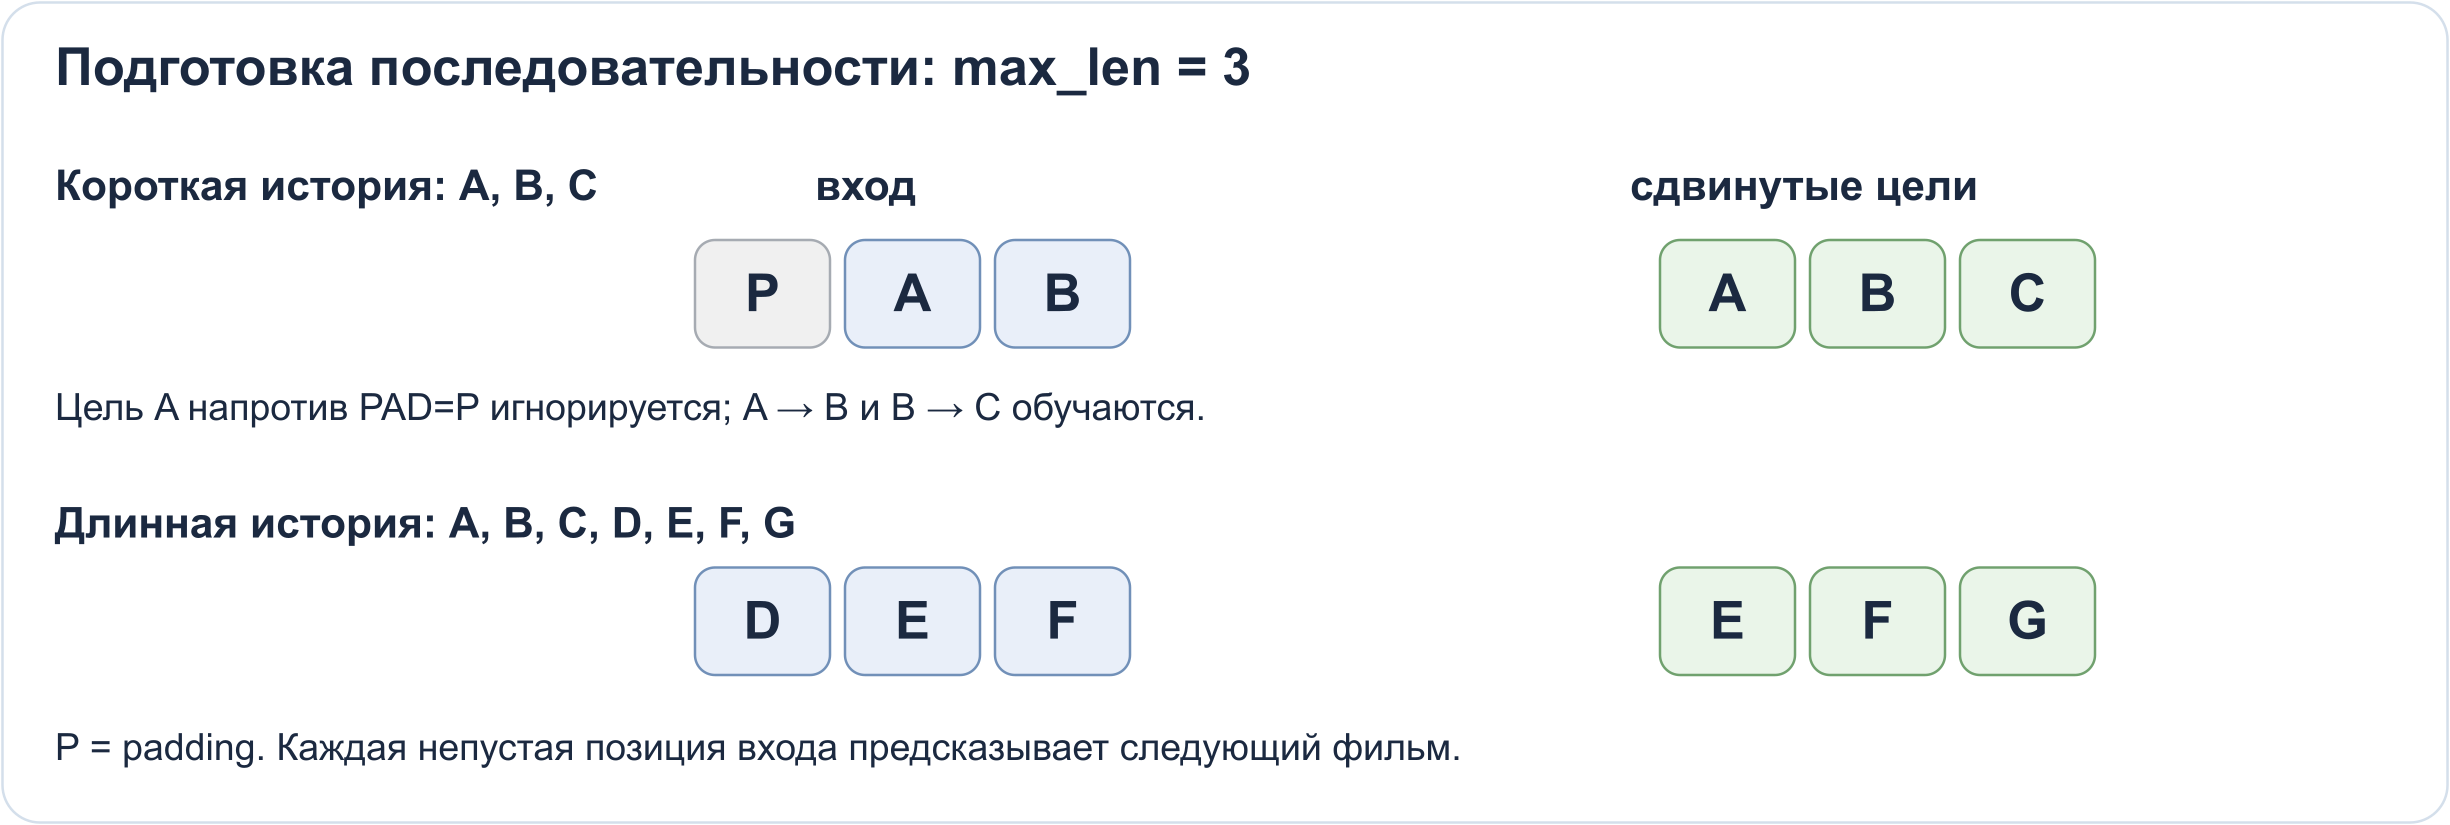

Цель напротив `PAD` игнорируется: реальными парами первой строки остаются `A → B`
и `B → C`. Во второй строке первая позиция `D` предсказывает `E`, затем `E → F`
и `F → G`. Causal attention не дает каждой позиции видеть следующие входные фильмы.
При обучении берется одна обрезанная последовательность на пользователя, без отдельных окон для каждого префикса. При прогнозе используются последние `max_len` событий доступной истории.

In [28]:
item_to_id = {int(item): i + 1 for i, item in enumerate(warm_items)}
id_to_item = {i: item for item, i in item_to_id.items()}
N_ITEMS = len(item_to_id)
assert N_ITEMS > max(KS)

def encode_items(rows):
    encoded = rows.copy()
    encoded[:, 1] = [item_to_id[int(item)] for item in rows[:, 1]]
    return encoded

train, val, test = [encode_items(rows) for rows in (train, val, test)]
train_val = np.concatenate([train, val])  # Уже упорядочены по времени.

def make_histories(rows):
    histories = defaultdict(list)
    for user, item, _, _ in rows:
        histories[int(user)].append(int(item))
    return dict(histories)

train_histories = make_histories(train)

class SequenceDataset(Dataset):
    def __init__(self, histories, max_len, padding_value):
        if max_len < 1:
            raise ValueError("max_len должен быть положительным")
        self.max_len = max_len
        self.padding_value = padding_value
        # Аналог одной строки train/input.txt на пользователя; весь ряд храним до __getitem__.
        self.sequences = [np.asarray(items, dtype=np.int64) for items in histories.values() if len(items) >= 2]

    def __len__(self):
        return len(self.sequences)

    def __getitem__(self, index):
        recent = self.sequences[index][-(self.max_len + 1):]
        positives = np.full(self.max_len + 1, self.padding_value, dtype=np.int64)
        positives[-len(recent):] = recent
        return torch.from_numpy(positives)

    def target_counts(self, n_items):
        # Частоты целей с непустыми входами после усечения до max_len + 1.
        counts = np.zeros(n_items + 1, dtype=np.int64)
        for items in self.sequences:
            recent = items[-(self.max_len + 1):]
            counts += np.bincount(recent[1:], minlength=n_items + 1)
        return counts

short = SequenceDataset({1: [1, 2, 3]}, max_len=3, padding_value=8)
long = SequenceDataset({1: [1, 2, 3, 4, 5, 6, 7]}, max_len=3, padding_value=8)
assert short[0].tolist() == [8, 1, 2, 3]
assert long[0].tolist() == [4, 5, 6, 7]
assert long.target_counts(7).tolist() == [0, 0, 0, 0, 0, 1, 1, 1]

train_dataset = SequenceDataset(train_histories, CFG["max_len"], N_ITEMS + 1)
positives = train_dataset[0]
print("Последовательностей:", len(train_dataset), "input:", positives[:-1][:15].tolist(),
      "target:", positives[1:][:15].tolist())
assert len(train_dataset) == len(train_histories)
assert train_dataset.target_counts(N_ITEMS).sum() == sum(min(len(h) - 1, CFG["max_len"])
                                                    for h in train_histories.values())

print("Пример [A, B, C]: input = [PAD, A, B], target = [A, B, C]")
print("Маска loss:", short[0][:-1].ne(8).tolist(), "- учитываются A -> B и B -> C")

Последовательностей: 5275 input: [2364, 820, 1902, 903, 947, 236, 1648, 1376, 904, 933, 644, 72, 2317, 2007, 2504] target: [820, 1902, 903, 947, 236, 1648, 1376, 904, 933, 644, 72, 2317, 2007, 2504, 1920]
Пример [A, B, C]: input = [PAD, A, B], target = [A, B, C]
Маска loss: [False, True, True] - учитываются A -> B и B -> C


## 5. SASRec

К эмбеддингам фильмов прибавляются эмбеддинги позиций. Два блока внимания обрабатывают историю с каузальной маской: на каждой позиции предсказывается следующий фильм.

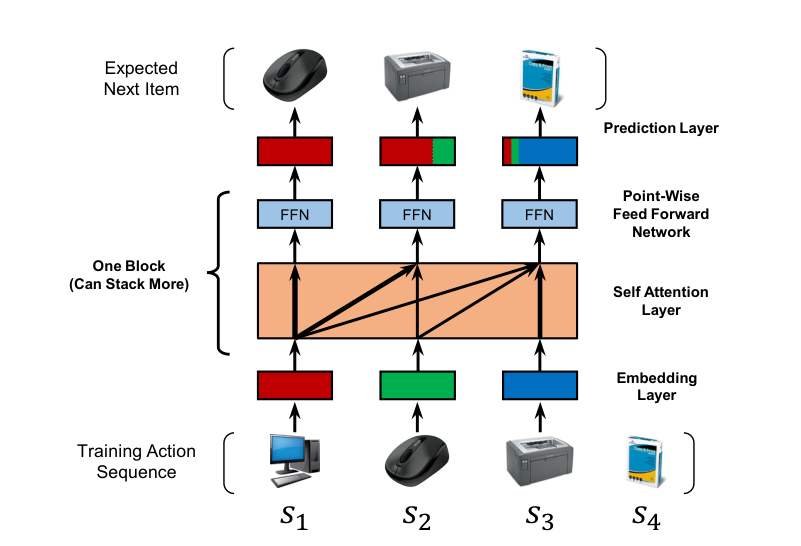

Источник: [Kang, McAuley, 2018, рис. 1](https://arxiv.org/abs/1808.09781). Для входа $[s_1,s_2,s_3]$ цели - $[s_2,s_3,s_4]$.

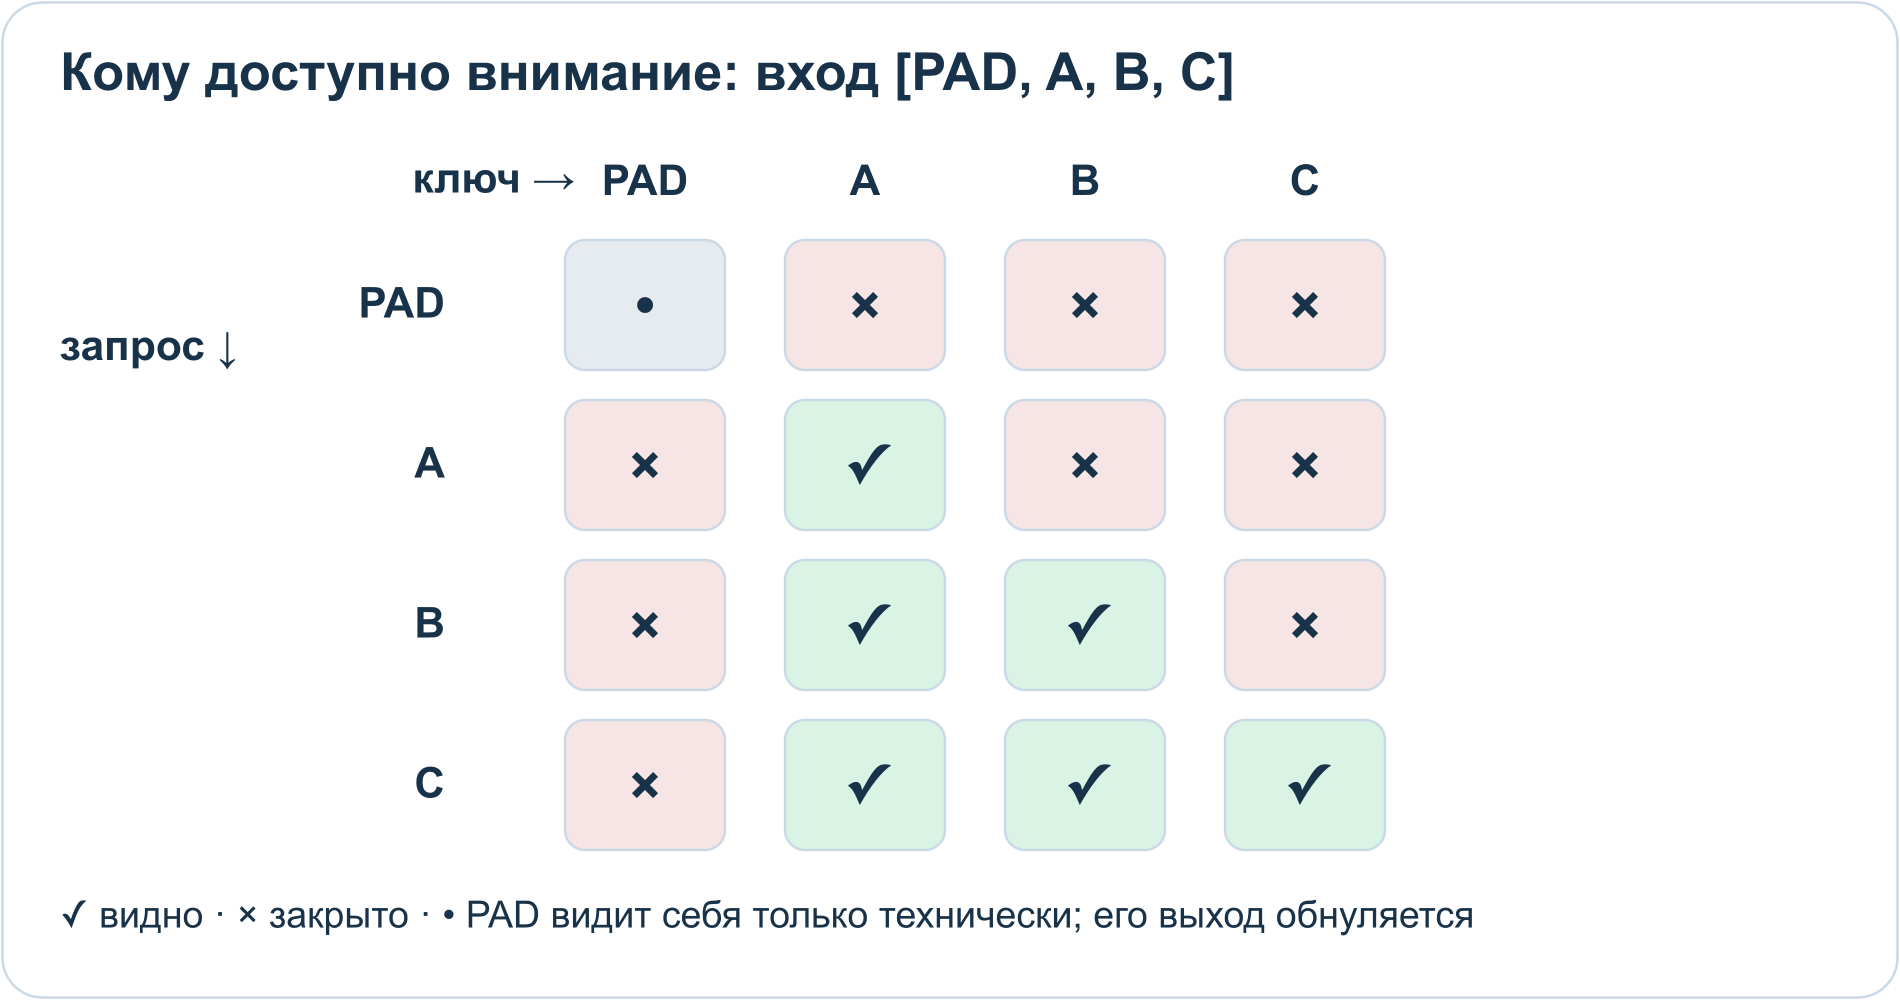

Строка маски - позиция запроса, столбец - позиция ключа. Настоящие позиции не видят `PAD`. Строке самого `PAD` технически разрешена диагональ, чтобы не получить softmax от одних $-\infty$; ее выход затем обнуляется.

В этой реализации запросы строятся из нормализованного входа $U=\operatorname{LN}_1(X)$, а ключи и значения - из $X$:

$$Q=\operatorname{Linear}_Q(U),\qquad K=\operatorname{Linear}_K(X),\qquad V=\operatorname{Linear}_V(X).$$

Результат внимания $H$ складывается с $U$, затем применяется вторая нормализация: $Y=\operatorname{LN}_2(U+H)$. Далее идут двухслойная сеть с ReLU и остаточное соединение; после всех блоков - заключительная LayerNorm. Код сохраняет эту схему SASRec.

Для рекомендации берем представление последней позиции $h$ и считаем $s(h,i)=h^\top E_{\mathrm{item}}(i)$. Вход и выход используют одну таблицу эмбеддингов фильмов. Уже встречавшиеся пользователю фильмы из выдачи исключаются.

In [29]:
class SASRecBlock(nn.Module):
    # Q/K/V формируются тремя слоями и делятся на головы; output projection нет.
    def __init__(self, dim, n_heads, dropout):
        super().__init__()
        if dim % n_heads:
            raise ValueError("dim должен делиться на число голов")
        self.n_heads = n_heads
        self.head_dim = dim // n_heads
        self.first_norm = nn.LayerNorm(dim)
        self.second_norm = nn.LayerNorm(dim)
        self.query_proj = nn.Linear(dim, dim)
        self.key_proj = nn.Linear(dim, dim)
        self.value_proj = nn.Linear(dim, dim)
        self.attention_dropout = nn.Dropout(dropout)
        self.dense1 = nn.Linear(dim, dim)
        self.dense2 = nn.Linear(dim, dim)
        self.dropout = nn.Dropout(dropout)

    def forward(self, seq, padding_mask):
        batch, length, dim = seq.shape
        queries = self.first_norm(seq)
        q = self.query_proj(queries).view(batch, length, self.n_heads, self.head_dim).transpose(1, 2)
        k = self.key_proj(seq).view(batch, length, self.n_heads, self.head_dim).transpose(1, 2)
        v = self.value_proj(seq).view(batch, length, self.n_heads, self.head_dim).transpose(1, 2)
        logits = (q @ k.transpose(-2, -1)) / math.sqrt(self.head_dim)
        causal = torch.triu(torch.ones(length, length, dtype=torch.bool, device=seq.device), diagonal=1)
        blocked = causal[None, None] | padding_mask[:, None, None, :]
        # PAD-query может видеть только себя; реальные query никогда не видят PAD-key.
        pad_diagonal = padding_mask[:, None, :, None] & torch.eye(length, dtype=torch.bool, device=seq.device)[None, None]
        blocked = blocked & ~pad_diagonal
        weights = torch.softmax(logits.masked_fill(blocked, -torch.inf), dim=-1)
        weights = weights.masked_fill(padding_mask[:, None, :, None], 0.0)
        attended = self.attention_dropout(weights) @ v
        attended = attended.transpose(1, 2).contiguous().view(batch, length, dim)
        x = self.second_norm(attended + queries)
        residual = x
        x = self.dense1(x)
        x = F.relu(x)
        x = self.dropout(x)
        x = self.dense2(x)
        x = self.dropout(x)
        return (x + residual).masked_fill(padding_mask.unsqueeze(-1), 0.0)


class SASRec(nn.Module):
    def __init__(self, n_items, max_len, dim=64, n_heads=1, n_layers=2, dropout=0.2):
        super().__init__()
        self.n_items = n_items
        self.max_len = max_len
        self.padding_value = n_items + 1
        self.item_embedding = nn.Embedding(n_items + 2, dim, padding_idx=self.padding_value)
        self.position_embedding = nn.Embedding(max_len, dim)
        self.embedding_dropout = nn.Dropout(dropout)
        self.blocks = nn.ModuleList([SASRecBlock(dim, n_heads, dropout) for _ in range(n_layers)])
        self.final_norm = nn.LayerNorm(dim)
        for module in self.modules():
            if isinstance(module, (nn.Embedding, nn.Linear)):
                nn.init.trunc_normal_(module.weight, std=0.02, a=-0.04, b=0.04)
                if isinstance(module, nn.Linear):
                    nn.init.zeros_(module.bias)
            elif isinstance(module, nn.LayerNorm):
                nn.init.ones_(module.weight)
                nn.init.zeros_(module.bias)
        with torch.no_grad():
            self.item_embedding.weight[self.padding_value].zero_()

    def forward(self, item_ids):
        # item_ids: [batch, max_len], результат: [batch, max_len, dim].
        batch, length = item_ids.shape
        if length > self.max_len:
            raise ValueError("Длина входа больше max_len")
        padding_mask = item_ids.eq(self.padding_value)
        if padding_mask.all(dim=1).any():
            raise ValueError("SASRec ожидает хотя бы одно событие в каждой истории")
        positions = torch.arange(length, device=item_ids.device)
        x = self.item_embedding(item_ids) + self.position_embedding(positions)
        x = self.embedding_dropout(x).masked_fill(padding_mask.unsqueeze(-1), 0.0)
        for block in self.blocks:
            x = block(x, padding_mask)
        return self.final_norm(x).masked_fill(padding_mask.unsqueeze(-1), 0.0)

    def score_items(self, hidden, item_ids):
        embeddings = self.item_embedding(item_ids)
        if item_ids.ndim == 1:
            return (hidden * embeddings).sum(-1)
        return (hidden[:, None, :] * embeddings).sum(-1)

    def score_catalog(self, hidden):
        # Каталог имеет ID 1..N; 0 и PAD=N+1 исключены.
        return hidden @ self.item_embedding.weight[1:self.n_items + 1].T

    @torch.no_grad()
    def predict(self, histories, k=10, batch_size=128, filter_seen=True):
        self.eval()
        if not 1 <= k <= self.n_items:
            raise ValueError("k должен быть внутри каталога")
        users = sorted(histories)
        predictions = {}
        device = self.item_embedding.weight.device
        for start in range(0, len(users), batch_size):
            batch_users = users[start:start + batch_size]
            inputs = np.full((len(batch_users), self.max_len), self.padding_value, dtype=np.int64)
            for row, user in enumerate(batch_users):
                recent = histories[user][-self.max_len:]
                if not recent:
                    raise ValueError("Холодный пользователь: нет истории")
                inputs[row, -len(recent):] = recent
            hidden = self(torch.as_tensor(inputs, device=device))
            scores = self.score_catalog(hidden[:, -1])
            if filter_seen:
                for row, user in enumerate(batch_users):
                    seen = torch.tensor(sorted(set(histories[user])), device=device) - 1
                    if self.n_items - len(seen) < k:
                        raise ValueError("После фильтрации просмотренных фильмов осталось меньше k кандидатов")
                    scores[row, seen] = -torch.inf
            top = torch.argsort(scores, dim=1, descending=True, stable=True)[:, :k] + 1
            for user, items in zip(batch_users, top.cpu().tolist()):
                predictions[user] = items
        return predictions


def new_model(seed):
    seed_everything(seed)
    return SASRec(N_ITEMS, CFG["max_len"], CFG["dim"], CFG["n_heads"],
                  CFG["n_layers"], CFG["dropout"]).to(DEVICE)

### Вопросы к последовательности

1. Для входа `[PAD, A, B]` и целей `[A, B, C]` по каким позициям считается loss?
2. Почему при обучении представление `A` не должно использовать входной `B`, хотя он находится в том же батче?

#### Ответы

1. По позициям `A` и `B`: они предсказывают `B` и `C`. Цель `A` напротив входного `PAD` не участвует.
2. Для позиции `A` фильм `B` является правильным следующим событием. Доступ к его входному эмбеддингу раскрыл бы ответ. Каузальная маска закрывает будущие позиции внутри каждой истории; другие истории батча внимание также не смешивает.

## 6. Негативы, распределение $Q$ и функции потерь

На каждой обучающей позиции известен **правильный следующий фильм** $y$.
Чтобы обучать модель без оценки всего каталога, берём ещё $K$ фильмов-кандидатов —
*негативы*. В коде это просто кандидаты, отличные от текущего правильного
фильма $y$. Мы не проверяем, встречался ли кандидат у этого пользователя
раньше или появится ли позже: выбранный фильм не обязательно ему неинтересен.
При `inbatch` кандидатами служат цели других позиций батча, в том числе
позиций с более поздними событиями. Для `full_softmax` отбор негативов не нужен:
он оценивает весь каталог.

Пусть $N$ — число фильмов в каталоге, а $c_i$ — сколько раз фильм $i$
встречается среди **обучающих целей** после подготовки последовательностей.
$Q(i)$ — вероятность, которую код подставляет в LogQ для фильма $i$.
Это характеристика выбора негативов, а не предсказание модели.

| Способ | Откуда берём каждый кандидат | $Q(i)$, используемое в LogQ |
|---|---|---|
| `uniform` | Случайный фильм из всего каталога | $1/N$ |
| `inbatch` | Случайная цель из текущего батча | Приближаем общими частотами $c_i/\sum_j c_j$ |
| `mixed` | Часть кандидатов — `uniform`, остальные — `inbatch` | Приближаем смесью $\lambda/N+(1-\lambda)c_i/\sum_j c_j$ |

Например, если цели в батче — `[B, C, C, D]`, то `inbatch` выбирает из
этого списка **с возвращением**: `C` выпадает вдвое чаще, чем `B` или `D`.
Точная вероятность для этого батча — $Q_{\mathcal B}(i)=b_i/B$, где $B$ —
число целей в батче, а $b_i$ — сколько среди них целей с фильмом $i$.
В поправке LogQ код заменяет её частотой по всем обучающим целям
$c_i/\sum_j c_j$, указанной в таблице.
При `mixed` и $K=4$ два кандидата берутся равномерно из каталога, ещё два —
из целей батча. В общем случае равномерных кандидатов $K_u=\lfloor K/2\rfloor$,
а $\lambda=K_u/K$ — их доля. Для случайно выбранного места среди $K$
кандидатов `mixed` вероятность фильма $i$ равна
$\lambda/N+(1-\lambda)Q_{\mathcal B}(i)$;
в LogQ вместо $Q_{\mathcal B}$ также используется частота по train.

Если выбранный кандидат совпал с правильным $y$, его **исключаем из loss**.
Повторения остальных кандидатов сохраняем: один фильм может попасть в выборку
несколько раз. Если все $K$ кандидатов совпали с $y$, эту позицию пропускаем.

В исходной статье SASRec негативы выбираются вне наблюдаемой истории пользователя. Здесь исключается только текущий правильный фильм $y$. При выдаче рекомендаций отфильтровывается полная доступная история.


In [30]:
class NegativeSampler:
    def __init__(self, counts, device):
        self.n_items = len(counts) - 1
        self.uniform = torch.zeros(len(counts), dtype=torch.float32, device=device)
        self.uniform[1:] = 1.0 / self.n_items
        frequencies = torch.as_tensor(counts, dtype=torch.float32, device=device)
        self.inbatch_q = frequencies / frequencies.sum()

    def sample(self, targets, k, strategy):
        m = len(targets)
        device = targets.device

        def uniform_sample(n):
            return torch.randint(1, self.n_items + 1, (m, n), device=device)

        def inbatch_sample(n):
            # Повторы сохраняем; совпадения с target позднее исключаем.
            indices = torch.randint(m, (m, n), device=device)
            return targets[indices]

        if strategy == "uniform":
            negatives, q = uniform_sample(k), self.uniform
        elif strategy == "inbatch":
            negatives, q = inbatch_sample(k), self.inbatch_q
        elif strategy == "mixed":
            uniform_k = k // 2
            negatives = torch.cat([uniform_sample(uniform_k), inbatch_sample(k - uniform_k)], dim=1)
            mixture_weight = uniform_k / k
            q = mixture_weight * self.uniform + (1 - mixture_weight) * self.inbatch_q
        else:
            raise ValueError(strategy)
        valid = negatives.ne(targets[:, None])
        return negatives, valid, q


### Функции потерь

Все формулы ниже относятся к **одной непустой позиции** обучающей последовательности.
Пусть $h$ - представление истории в этой позиции, $y$ - действительно следующий
фильм, а $s(h,i)$ - оценка фильма $i$ моделью. Обозначим $s_+=s(h,y)$.
После отбора негативов и удаления совпадений с $y$ остаются фильмы
$n_1,\ldots,n_m$ с оценками $s_j=s(h,n_j)$. Здесь $m$ - число **оставшихся
экземпляров**: если фильм выбран дважды, оба экземпляра входят в суммы.
$N$ - число фильмов в каталоге. Loss усредняется по пригодным позициям батча;
позиции `PAD` и позиции без оставшихся негативов в sampled loss не участвуют.

Используем функции
$\sigma(x)=1/(1+e^{-x})$ (**sigmoid**) и
$\operatorname{softplus}(x)=\log(1+e^x)$. Для устойчивого вычисления суммы
экспонент в коде применяется
$\operatorname{logsumexp}(x_1,\ldots,x_r)=\log\sum_{j=1}^{r}e^{x_j}$.
Значение $Q(i)$ из предыдущей части раздела - вероятность **выбрать** фильм
sampler; его не следует путать с оценкой $s(h,i)$ или вероятностью модели.

#### BCE: отдельное решение для каждого фильма

BCE (binary cross-entropy) трактует правильный фильм как класс 1, а каждый
выбранный негатив - как класс 0. Модель переводит оценку $s$ в число от 0 до 1
с помощью $\sigma(s)$. Для одной позиции:

$$L_{\mathrm{BCE}}=-\frac{1}{m+1}\left[
\log\sigma(s_+)+\sum_{j=1}^{m}\log\bigl(1-\sigma(s_j)\bigr)\right]
=\frac{\operatorname{softplus}(-s_+)+
\sum_{j=1}^{m}\operatorname{softplus}(s_j)}{m+1}.$$

Знаменатель $m+1$ усредняет вклад одного позитива и $m$ негативов.
Минимизация повышает $s_+$ и понижает $s_j$. Каждый фильм оценивается
**независимо**: значения $\sigma(s(h,i))$ по каталогу не обязаны суммироваться
в 1. При малом числе негативов это может вести к переоценке вероятностей
популярных кандидатов - мотивация [gBCE в статье gSASRec](https://arxiv.org/pdf/2308.07192).

#### gBCE: уменьшаем вклад положительного примера

gBCE (generalised BCE) меняет **только положительное слагаемое** BCE:

$$L_{\mathrm{gBCE}}=-\frac{1}{m+1}\left[
\log\bigl(\sigma(s_+)^{\beta}\bigr)+
\sum_{j=1}^{m}\log\bigl(1-\sigma(s_j)\bigr)\right]
=\frac{\beta\operatorname{softplus}(-s_+)+
\sum_{j=1}^{m}\operatorname{softplus}(s_j)}{m+1}.$$

$\beta$ - вес положительного слагаемого. В ноутбуке он вычисляется отдельно
для каждой позиции:

$$\alpha=\frac{m}{N-1},\qquad
\beta=(1-t)\cdot1+t\cdot\alpha=1-t+t\alpha,\qquad 0\le t\le1.$$

$N-1$ - число фильмов, отличных от $y$; $\alpha$ сопоставляет число
негативных слагаемых с размером оставшегося каталога. Из-за повторов это
не обязательно доля **уникальных** просмотренных фильмов. $t$ задает,
насколько далеко от BCE мы
сдвигаемся: при $t=0$ получаем $\beta=1$ и обычный BCE; при $t=1$ -
$\beta=\alpha$. В конфигурации ноутбука `gbce_t=0.75`.
После отбрасывания совпадений с $y$ код использует фактическое $m$, а не
исходное $K$ запросов к sampler. Интерпретация $\beta=\alpha$ как калибровки
верна при предпосылках статьи, прежде всего равномерном выборе негативов.

#### Full и sampled softmax: один выбор среди кандидатов

В отличие от BCE, softmax нормирует оценки по **взаимоисключающим вариантам**.
Полный softmax использует все $N$ фильмов:

$$P_{\mathrm{full}}(y\mid h)=
\frac{e^{s_+}}{\sum_{i=1}^{N}e^{s(h,i)}},\qquad
L_{\mathrm{full}}=-\log P_{\mathrm{full}}(y\mid h)
=-s_++\log\sum_{i=1}^{N}e^{s(h,i)}.$$

Знаменатель учитывает весь каталог, поэтому негативный sampler не нужен.
Sampled softmax оставляет в знаменателе только позитив и $m$ выбранных
негативов:

$$P_{\mathrm{sampled}}(y\mid h,n_{1:m})=
\frac{e^{s_+}}{e^{s_+}+\sum_{j=1}^{m}e^{s_j}},\qquad
L_{\mathrm{sampled}}=-s_++
\log\left(e^{s_+}+\sum_{j=1}^{m}e^{s_j}\right).$$

Так дешевле считать loss, но это вероятность **среди выбранных кандидатов**,
а не по всему каталогу. Если популярные фильмы часто попадают в негативы,
они чаще штрафуются. Поэтому результат sampled softmax зависит от $Q$.

#### Стандартный LogQ: учитываем, как выбирали негативы

В sampled softmax частый кандидат попадает в негативы чаще и чаще получает
штраф. LogQ учитывает вероятность его выбора $Q(i)$: вместо оценки
$s(h,i)$ использует $a(h,i)=s(h,i)-\log Q(i)$. Поэтому при одинаковой
оценке модели редко выбираемый фильм получает большую исправленную оценку:
$e^{a(h,i)}=e^{s(h,i)}/Q(i)$. Здесь $Q$ задает **sampler**, а не модель.

Обозначим исправленные оценки позитива и негативов через
$a_+=s_+-\log Q(y)$ и $a_j=s_j-\log Q(n_j)$. В коде ноутбука loss -
softmax по этим оценкам:

$$L_{\mathrm{logq}}=-\log\frac{e^{a_+}}{e^{a_+}+\sum_{j=1}^{m}e^{a_j}}
=-a_++\log\left(e^{a_+}+\sum_{j=1}^{m}e^{a_j}\right).$$

Если $Q$ равномерно, из каждой оценки вычитается одно и то же число;
оно сокращается и получается обычный sampled softmax. В стандартном LogQ
поправка применяется и к позитиву $y$, хотя он добавлен в пример заранее.
Ограничение этой поправки и исправленный вариант приведены в бонусе.

In [31]:
def sampled_loss(positive, negative, valid, q_positive, q_negative, kind, n_items, gbce_t):
    # Все тензоры уже относятся к непустым позициям последовательностей.
    counts = valid.sum(dim=1)
    usable = counts > 0
    if not usable.any():
        # Соединенный с графом ноль: безопасен даже для батча одинаковых target.
        return positive.sum() * 0.0
    positive, negative = positive[usable], negative[usable]
    valid, counts = valid[usable], counts[usable].to(positive.dtype)
    q_positive, q_negative = q_positive[usable], q_negative[usable]

    if kind in ("bce", "gbce"):
        beta = 1.0 if kind == "bce" else 1.0 - gbce_t + gbce_t * counts / (n_items - 1)
        negative_term = F.softplus(negative).masked_fill(~valid, 0.0).sum(dim=1)
        return ((beta * F.softplus(-positive) + negative_term) / (counts + 1)).mean()

    negative = negative.masked_fill(~valid, -torch.inf)
    if kind == "sampled_softmax":
        positive_logit, negative_logits = positive, negative
    elif kind == "logq":
        positive_logit = positive - q_positive.clamp_min(1e-12).log()
        negative_logits = negative - q_negative.clamp_min(1e-12).log()
    elif kind == "corrected":
        q_conditional = q_negative / (1 - q_positive[:, None]).clamp_min(1e-12)
        log_negative_sum = torch.logsumexp(negative - q_conditional.clamp_min(1e-12).log(), dim=1)
        # w = 1 - P_positive; sigmoid в такой форме избегает вычитания близких чисел.
        weight = torch.sigmoid(log_negative_sum - counts.log() - positive).detach()
        return (weight * (log_negative_sum - positive)).mean()
    else:
        raise ValueError(kind)
    logits = torch.cat([positive_logit[:, None], negative_logits], dim=1)
    return F.cross_entropy(logits, torch.zeros(len(positive), dtype=torch.long, device=positive.device))


def training_loss(model, inputs, targets, sampler, experiment):
    hidden = model(inputs)
    mask = inputs.ne(model.padding_value)
    hidden, targets = hidden[mask], targets[mask]
    if experiment["loss"] == "full_softmax":
        return F.cross_entropy(model.score_catalog(hidden), targets - 1)
    negatives, valid, q = sampler.sample(targets, experiment["n_neg"], experiment["sampling"])
    positive_scores = model.score_items(hidden, targets)
    negative_scores = model.score_items(hidden, negatives)
    return sampled_loss(positive_scores, negative_scores, valid, q[targets], q[negatives],
                        experiment["loss"], model.n_items, CFG["gbce_t"])

## 7. Протокол рекомендаций и метрики

Для validation история пользователя содержит только события train, для test - события train + val.

Ground truth $G_u$ - **множество фильмов пользователя в его первый активный день после границы** (календарный день UTC): для validation - после `val_start`, для test - после `test_start`. Так моделируется ежедневный пересчет рекомендаций: события внутри дня модель учесть не успевает, поэтому все фильмы этого дня - одна цель.

Пусть $H_u$ - множество фильмов из доступной истории пользователя $u$, а $R_u@k=(i_{u1},\ldots,i_{uk})$ - упорядоченный список из $k$ рекомендованных фильмов. Ранее просмотренные фильмы в рекомендации не попадают. Обозначим $r_{uj}=1$, если фильм на месте $j$ входит в $G_u$, и $r_{uj}=0$ иначе. Тогда $h_{uj}=\sum_{l=1}^{j}r_{ul}$ - число попаданий среди первых $j$ рекомендаций. $\mathcal U$ - оцениваемые пользователи, $N$ - число фильмов в каталоге. Все метрики, кроме Coverage, усредняются по пользователям.

**Recall@k** - доля фильмов из $G_u$, попавших в первые $k$ рекомендаций:

$$Recall_u@k=\frac{h_{uk}}{|G_u|}.$$

**NDCG@k** (Normalized Discounted Cumulative Gain) выше, когда релевантные фильмы стоят ближе к началу списка. Знаменатель - лучший возможный результат для данного пользователя:

$$DCG_u@k=\sum_{j=1}^{k}\frac{r_{uj}}{\log_2(j+1)},\qquad
NDCG_u@k=\frac{DCG_u@k}{\sum_{j=1}^{\min(k,|G_u|)}1/\log_2(j+1)}.$$

**Coverage@k** - доля каталога, появившаяся хотя бы у одного пользователя:

$$Coverage@k=\frac{\left|\bigcup_{u\in\mathcal U}\{i_{u1},\ldots,i_{uk}\}\right|}{N}.$$


В основной таблице оставляем NDCG@10, Recall@10 и Coverage@10. Первые две метрики оценивают попадания в отложенные события, третья - широту выдачи по каталогу. Высокое покрытие само по себе не означает, что рекомендации релевантны.

In [32]:
def make_evaluation_data(history_rows, future_rows, name):
    histories = make_histories(history_rows)
    assert (np.diff(future_rows[:, 3]) >= 0).all()
    days = future_rows[:, 3].astype("datetime64[s]").astype("datetime64[D]")
    _, first_index, inverse = np.unique(future_rows[:, 0], return_index=True, return_inverse=True)
    future_rows = future_rows[days == days[first_index][inverse]]
    future = make_histories(future_rows)
    truth, unseen_truth = {}, {}
    empty_unseen = 0
    for user, items in future.items():
        if user not in histories:
            continue
        truth[user] = set(items)
        unseen_truth[user] = truth[user] - set(histories[user])
        empty_unseen += not unseen_truth[user]
    print(f"{name}: пользователей для оценки={len(truth)}, без новых для себя фильмов={empty_unseen}")
    if not truth:
        raise ValueError("Нет пользователей для оценки")
    return {user: histories[user] for user in truth}, truth, unseen_truth

val_histories, val_truth, val_unseen_truth = make_evaluation_data(train, val, "val")
test_histories, test_truth, test_unseen_truth = make_evaluation_data(train_val, test, "test")

class RecommendationMetrics:
    def __init__(self, history_rows, n_items):
        self.n_items = n_items
        self.counts = np.bincount(history_rows[:, 1], minlength=n_items + 1)
        pairs = np.unique(history_rows[:, :2], axis=0)
        item_users = np.bincount(pairs[:, 1], minlength=n_items + 1)
        n_users = len(np.unique(history_rows[:, 0]))
        self.novelty = np.zeros(n_items + 1)
        observed = item_users > 0
        self.novelty[observed] = np.log2(n_users / item_users[observed])
        count_to_rank = {int(count): rank + 1 for rank, count in enumerate(sorted(set(self.counts[1:]), reverse=True))}
        self.pop_rank = np.zeros(n_items + 1)
        for item in range(1, n_items + 1):
            self.pop_rank[item] = count_to_rank[int(self.counts[item])] if self.counts[item] else n_items + 1

    def calculate(self, predictions, truth, unseen_truth, ks=(5, 10, 20)):
        if not truth or set(predictions) != set(truth) or set(unseen_truth) != set(truth):
            raise ValueError("Нужна выдача и оба ground truth для каждого пользователя")
        result = {}
        for k in ks:
            values = defaultdict(list)
            recommended = set()
            ranks = np.arange(1, k + 1)
            discounts = 1 / np.log2(ranks + 1)
            for user, relevant in truth.items():
                items = np.asarray(predictions[user][:k], dtype=np.int64)
                if len(items) != k or len(set(items)) != k or not relevant:
                    raise ValueError("Ожидаем k разных рекомендаций и непустой ground truth")
                if not ((items >= 1) & (items <= self.n_items)).all():
                    raise ValueError("Рекомендация за пределами каталога")
                recommended.update(items.tolist())
                hits = np.asarray([item in relevant for item in items], dtype=np.float64)
                tp = float(hits.sum())
                precision, recall = tp / k, tp / len(relevant)
                ideal_dcg = discounts[:min(k, len(relevant))].sum()
                values["NDCG"].append(float(hits @ discounts / ideal_dcg))
                values["MAP"].append(float((hits * np.cumsum(hits) / ranks).sum() / len(relevant)))
                hit_positions = np.flatnonzero(hits)
                values["MRR"].append(1 / (hit_positions[0] + 1) if len(hit_positions) else 0.0)
                values["Precision"].append(precision)
                values["Recall"].append(recall)
                unseen = unseen_truth[user]
                if not unseen.issubset(relevant):
                    raise ValueError("Unseen ground truth должен быть подмножеством полного")
                if unseen:
                    values["UnseenRecall"].append(sum(item in unseen for item in items) / len(unseen))
                values["MIUF"].append(float(self.novelty[items].mean()))
                values["Serendipity"].append(float((hits * np.maximum((self.pop_rank[items] - ranks) / self.n_items, 0)).mean()))
            result.update({f"{name}@{k}": float(np.mean(per_user)) for name, per_user in values.items()})
            result[f"UnseenRecall@{k}"] = (float(np.mean(values["UnseenRecall"]))
                                           if values["UnseenRecall"] else float("nan"))
            result[f"Coverage@{k}"] = len(recommended) / self.n_items
        return result

    @staticmethod
    def ndcg_at_k(predictions, truth, k=10):
        # Во время early stopping вычисляем только NDCG.
        discounts = 1 / np.log2(np.arange(2, k + 2))
        scores = []
        for user, relevant in truth.items():
            hits = np.asarray([item in relevant for item in predictions[user][:k]])
            scores.append(float(hits @ discounts / discounts[:min(k, len(relevant))].sum()))
        return float(np.mean(scores))

genres = {item: movie_metadata[raw_id]["genres"] for item, raw_id in id_to_item.items()}
val_metrics = RecommendationMetrics(train, N_ITEMS)
test_metrics = RecommendationMetrics(train_val, N_ITEMS)

val: пользователей для оценки=492, без новых для себя фильмов=0
test: пользователей для оценки=921, без новых для себя фильмов=0


## 8. Цикл обучения и early stopping

После каждой эпохи считаем full-catalog validation NDCG@10.
Улучшение должно превышать `min_delta`; после `patience` эпох без улучшения останавливаемся.
Для test используем модель лучшей эпохи, обученную только на train. `max_epochs` - дополнительный предел времени.

Для каждого loss и sampler используем одну архитектуру, одинаковый seed и бюджет обучения.
В `demo` эпоха ограничена `max_batches`: это **не** полный проход по всем пользователям.
В `full` ограничение снято.
Loss разных семейств нельзя сравнивать численно: сравнивайте validation метрику.

In [33]:
class EarlyStopping:
    def __init__(self, patience, min_delta):
        self.patience = patience
        self.min_delta = min_delta
        self.best_score = -math.inf
        self.best_epoch = 0
        self.bad_epochs = 0

    def update(self, score, epoch):
        improved = score > self.best_score + self.min_delta
        if improved:
            self.best_score, self.best_epoch, self.bad_epochs = score, epoch, 0
        else:
            self.bad_epochs += 1
        return improved, self.bad_epochs >= self.patience

# Проверим точный момент остановки на искусственном ряду метрик.
stopper_example = EarlyStopping(patience=2, min_delta=0.001)
assert stopper_example.update(0.1, 1) == (True, False)
assert stopper_example.update(0.1005, 2) == (False, False)
assert stopper_example.update(0.099, 3) == (False, True)
assert stopper_example.best_epoch == 1


def make_loader(dataset, seed):
    generator = torch.Generator().manual_seed(seed)
    return DataLoader(dataset, batch_size=CFG["batch_size"], shuffle=True,
                      num_workers=0, drop_last=False, generator=generator)


def train_one_epoch(model, loader, optimizer, sampler, experiment):
    model.train()
    loss_sum, batches = 0.0, 0
    for positives in loader:
        positives = positives.to(DEVICE)
        inputs, targets = positives[:, :-1], positives[:, 1:]
        optimizer.zero_grad(set_to_none=True)
        loss = training_loss(model, inputs, targets, sampler, experiment)
        if not torch.isfinite(loss):
            raise FloatingPointError(f"Нечисловой loss: {experiment['name']}")
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0, error_if_nonfinite=True)
        optimizer.step()
        loss_sum += loss.item()
        batches += 1
        if CFG["max_batches"] is not None and batches >= CFG["max_batches"]:
            break
    if batches == 0:
        raise ValueError("Пустой DataLoader")
    return loss_sum / batches


def select_epoch(experiment, seed, trial_dir):
    model = new_model(seed)
    loader = make_loader(train_dataset, seed)
    sampler = NegativeSampler(train_dataset.target_counts(N_ITEMS), DEVICE)
    optimizer = torch.optim.Adam(model.parameters(), lr=CFG["learning_rate"])
    stopper = EarlyStopping(CFG["patience"], CFG["min_delta"])
    history = []
    checkpoint_path = trial_dir / "best_validation.pt"
    for epoch in range(1, CFG["max_epochs"] + 1):
        started = time.perf_counter()
        loss = train_one_epoch(model, loader, optimizer, sampler, experiment)
        predictions = model.predict(val_histories, k=10, batch_size=CFG["eval_batch_size"])
        score = RecommendationMetrics.ndcg_at_k(predictions, val_truth, k=10)
        improved, stop = stopper.update(score, epoch)
        if improved:
            torch.save(model.state_dict(), checkpoint_path)
        history.append(dict(epoch=epoch, loss=loss, val_ndcg10=score,
                            seconds=time.perf_counter() - started, improved=improved))
        print(f"  epoch={epoch:3d} loss={loss:.4f} val NDCG@10={score:.5f}" + (" *" if improved else ""))
        if stop:
            break
    model.load_state_dict(torch.load(checkpoint_path, map_location=DEVICE, weights_only=True))
    return model, stopper.best_epoch, stopper.best_score, history

## 9. Сравнение функций потерь

Сначала сравним BCE и gBCE при равномерном выборе негативов, затем используем sampled softmax с равномерными негативами как базовую конфигурацию и сравниваем sampled softmax и стандартный LogQ отдельно для `inbatch` и `mixed`. Внутри каждой пары одинаковы архитектура, начальные веса, seed, число негативов и бюджет обучения. Лучшая эпоха каждой модели выбирается по validation NDCG@10.

Global TopPop рекомендует самые частые фильмы из train и исключает уже встречавшиеся пользователю. Это ориентир, с которым сравниваем обучаемые модели.

Веса всех моделей обучаются только на train. Для test в историю добавляются события val, без дообучения на них. Test используется для итоговой оценки.

In [34]:
EXPERIMENTS = [
    dict(name="bce__uniform", loss="bce", sampling="uniform", n_neg=CFG["n_neg"]),
    dict(name="gbce__uniform", loss="gbce", sampling="uniform", n_neg=CFG["n_neg"]),
    dict(name="sampled_softmax__uniform", loss="sampled_softmax", sampling="uniform", n_neg=CFG["n_neg"]),
]
for sampling in ("inbatch", "mixed"):
    for loss in ("sampled_softmax", "logq"):
        EXPERIMENTS.append(dict(name=f"{loss}__{sampling}", loss=loss,
                                sampling=sampling, n_neg=CFG["n_neg"]))
assert len(EXPERIMENTS) == 7
print("Основных конфигураций:", len(EXPERIMENTS), "seed:", SEEDS)


Основных конфигураций: 7 seed: [42]


In [35]:
def popularity_predict(history_rows, query_histories, k):
    counts = np.bincount(history_rows[:, 1], minlength=N_ITEMS + 1)
    order = np.argsort(-counts[1:], kind="stable") + 1
    predictions = {}
    for user, history in query_histories.items():
        seen = set(history)
        predictions[user] = [int(item) for item in order if item not in seen][:k]
    return predictions


def genre_weighted_top_pop_predict(train_rows, query_histories, genres, k):
    counts = np.bincount(train_rows[:, 1], minlength=N_ITEMS + 1)
    genre_names = sorted({genre for labels in genres.values() for genre in labels})
    genre_to_column = {genre: column for column, genre in enumerate(genre_names)}
    genre_matrix = np.zeros((N_ITEMS + 1, len(genre_names)), dtype=np.float32)
    for item, labels in genres.items():
        if labels:
            for genre in labels:
                genre_matrix[item, genre_to_column[genre]] = 1.0 / len(labels)

    predictions = {}
    item_ids = np.arange(1, N_ITEMS + 1)
    for user, history in query_histories.items():
        profile = genre_matrix[np.asarray(history, dtype=np.int64)].sum(axis=0)
        if profile.sum() > 0:
            profile /= profile.sum()
            scores = counts[1:] * (genre_matrix[1:] @ profile)
        else:
            scores = counts[1:]
        # При равном score выше стоит более популярный фильм; затем меньший item id.
        order = np.lexsort((item_ids, -counts[1:], -scores)) + 1
        seen = set(history)
        predictions[user] = [int(item) for item in order if item not in seen][:k]
    return predictions


def save_csv(path, rows):
    if not rows:
        return
    # Объединение ключей позволяет baseline иметь ту же таблицу, что и нейросети.
    columns = list(dict.fromkeys(key for row in rows for key in row))
    with Path(path).open("w", encoding="utf-8", newline="") as file:
        writer = csv.DictWriter(file, fieldnames=columns)
        writer.writeheader()
        writer.writerows(rows)

In [36]:
pop_val = popularity_predict(train, val_histories, max(KS))
pop_test = popularity_predict(train, test_histories, max(KS))
pop_val_score = RecommendationMetrics.ndcg_at_k(pop_val, val_truth, 10)
results = [dict(name="global_top_pop", loss="none", sampling="none", n_neg=0,
                seed=None, best_epoch=0, val_ndcg10=pop_val_score, seconds=0.0,
                **test_metrics.calculate(pop_test, test_truth, test_unseen_truth, KS))]

manifest = dict(mode=MODE, config=CFG, seeds=SEEDS, device=str(DEVICE),
                numpy=np.__version__, torch=torch.__version__, dataset_url=MOVIELENS_URL,
                dataset_md5=actual_md5, val_start=val_start, test_start=test_start,
                events=dict(train=len(train), val=len(val), test=len(test)),
                evaluation_users=dict(val=len(val_truth), test=len(test_truth)),
                n_items=N_ITEMS, experiments=EXPERIMENTS)
(OUTPUT_DIR / "manifest.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
(OUTPUT_DIR / "item_mapping.json").write_text(json.dumps(id_to_item, indent=2), encoding="utf-8")
print(f"Global TopPop: val NDCG@10={pop_val_score:.5f}; "
      f"test NDCG@10={results[0]['NDCG@10']:.5f}; "
      f"Recall@10={results[0]['Recall@10']:.5f}; Coverage@10={results[0]['Coverage@10']:.4f}")

Global TopPop: val NDCG@10=0.08911; test NDCG@10=0.08547; Recall@10=0.03781; Coverage@10=0.0511


In [37]:
def run_experiments(experiments, output_dir):
    rows = []
    for experiment in experiments:
        for seed in SEEDS:
            started = time.perf_counter()
            print(f"\n{experiment['name']} | seed={seed}")
            trial_dir = output_dir / f"{experiment['name']}__seed{seed}"
            trial_dir.mkdir(parents=True, exist_ok=True)
            model, best_epoch, best_score, history = select_epoch(experiment, seed, trial_dir)
            save_csv(trial_dir / "learning_curve.csv", history)
            predictions = model.predict(test_histories, k=max(KS), batch_size=CFG["eval_batch_size"])
            metrics = test_metrics.calculate(predictions, test_truth, test_unseen_truth, KS)
            result = dict(**experiment, seed=seed, best_epoch=best_epoch, val_ndcg10=best_score,
                          seconds=time.perf_counter() - started, **metrics)
            rows.append(result)
            save_csv(output_dir / "test_metrics.csv", rows)
            print(f"  best epoch={best_epoch}; test NDCG@10={metrics['NDCG@10']:.5f}; Recall@10={metrics['Recall@10']:.5f}; Coverage@10={metrics['Coverage@10']:.4f}; time={result['seconds']:.1f}s")
            del model

    return rows

### 9.1. BCE и gBCE: равномерные негативы

Проверяем влияние веса положительного примера. Меняется только функция потерь: в gBCE положительное слагаемое умножается на $\beta$. Уменьшение самого значения loss еще не означает улучшения рекомендаций.

In [38]:
results.extend(run_experiments(EXPERIMENTS[:2], OUTPUT_DIR))
save_csv(OUTPUT_DIR / "test_metrics.csv", results)


bce__uniform | seed=42
  epoch=  1 loss=0.2378 val NDCG@10=0.09159 *
  epoch=  2 loss=0.0462 val NDCG@10=0.09282 *
  epoch=  3 loss=0.0423 val NDCG@10=0.09464 *
  epoch=  4 loss=0.0415 val NDCG@10=0.09228
  epoch=  5 loss=0.0412 val NDCG@10=0.09436
  epoch=  6 loss=0.0411 val NDCG@10=0.09457
  epoch=  7 loss=0.0411 val NDCG@10=0.09211
  epoch=  8 loss=0.0410 val NDCG@10=0.09279
  best epoch=3; test NDCG@10=0.08731; Recall@10=0.03984; Coverage@10=0.0449; time=99.4s

gbce__uniform | seed=42
  epoch=  1 loss=0.2259 val NDCG@10=0.08975 *
  epoch=  2 loss=0.0231 val NDCG@10=0.09047 *
  epoch=  3 loss=0.0169 val NDCG@10=0.09133 *
  epoch=  4 loss=0.0154 val NDCG@10=0.09221 *
  epoch=  5 loss=0.0149 val NDCG@10=0.09217
  epoch=  6 loss=0.0147 val NDCG@10=0.09385 *
  epoch=  7 loss=0.0145 val NDCG@10=0.09301
  epoch=  8 loss=0.0145 val NDCG@10=0.09314
  epoch=  9 loss=0.0144 val NDCG@10=0.09225
  epoch= 10 loss=0.0144 val NDCG@10=0.09278
  epoch= 11 loss=0.0144 val NDCG@10=0.09353
  best epoc

### Обсуждение BCE и gBCE

1. Почему более низкий loss gBCE не доказывает, что рекомендации стали лучше?
2. Что показывает разница NDCG@10 при одинаковом sampler и числе негативов? Достаточно ли одного seed, чтобы объявить один loss лучшим?

#### Ответы

1. В gBCE изменен вес положительного слагаемого, поэтому шкала loss другая. Сравнивать качество нужно по одинаковым метрикам на одинаковых данных.
2. В этой паре различие связано с изменением функции потерь и последующим обучением, а не со сменой архитектуры или sampler. Но один короткий запуск не позволяет оценить устойчивость результата; для этого нужны несколько seed и достаточный бюджет, выбранный без настройки по test.

### 9.2. Sampled softmax: uniform, in-batch и mixed; сравнение с LogQ

Сначала обучаем sampled softmax с `uniform` как базовую конфигурацию для оценки влияния sampler.

Сравниваем sampled softmax и стандартный LogQ отдельно для двух sampler:
- `inbatch`: кандидаты выбираются из целей текущего батча с возвращением;
- `mixed`: половина кандидатов выбирается равномерно из каталога, остальные — из целей батча.

Внутри каждой пары одинаковы seed, архитектура, бюджет и способ выбора негативов.
LogQ вычитает $\log Q(i)$ из оценок перед вычислением loss. Для `inbatch` и
`mixed` используется приближение $Q$ по глобальным частотам обучающих целей,
как в исходном ноутбуке; точное распределение текущего батча может отличаться.
При выдаче рекомендаций используются исходные оценки $s(h,i)$.

Для равномерного $Q$ поправка одинакова для всех кандидатов и сокращается.
Проверим это на фиксированных оценках, без отдельного обучения LogQ с `uniform`: он эквивалентен sampled softmax с `uniform`.


In [39]:
scores_pos = torch.tensor([0.7, -0.2])
scores_neg = torch.tensor([[0.1, -0.5, 0.3], [0.4, 0.8, -0.1]])
valid_example = torch.ones_like(scores_neg, dtype=torch.bool)
q_pos = torch.full_like(scores_pos, 1.0 / N_ITEMS)
q_neg = torch.full_like(scores_neg, 1.0 / N_ITEMS)
losses_example = [sampled_loss(scores_pos, scores_neg, valid_example, q_pos, q_neg,
                             kind, N_ITEMS, CFG["gbce_t"])
                  for kind in ("sampled_softmax", "logq")]
torch.testing.assert_close(*losses_example)
print("Uniform: sampled softmax =", round(losses_example[0].item(), 6),
      "; LogQ =", round(losses_example[1].item(), 6))

Uniform: sampled softmax = 1.409169 ; LogQ = 1.40917


In [40]:
results.extend(run_experiments(EXPERIMENTS[2:], OUTPUT_DIR))
save_csv(OUTPUT_DIR / "test_metrics.csv", results)


sampled_softmax__uniform | seed=42
  epoch=  1 loss=4.4136 val NDCG@10=0.11328 *
  epoch=  2 loss=3.8287 val NDCG@10=0.10281
  epoch=  3 loss=3.3278 val NDCG@10=0.09795
  epoch=  4 loss=3.0806 val NDCG@10=0.09399
  epoch=  5 loss=2.9411 val NDCG@10=0.09586
  epoch=  6 loss=2.8633 val NDCG@10=0.09434
  best epoch=1; test NDCG@10=0.09888; Recall@10=0.05306; Coverage@10=0.0836; time=77.9s

sampled_softmax__inbatch | seed=42
  epoch=  1 loss=4.6590 val NDCG@10=0.07568 *
  epoch=  2 loss=4.0489 val NDCG@10=0.05137
  epoch=  3 loss=3.7388 val NDCG@10=0.03869
  epoch=  4 loss=3.5551 val NDCG@10=0.03859
  epoch=  5 loss=3.4511 val NDCG@10=0.03674
  epoch=  6 loss=3.3909 val NDCG@10=0.03709
  best epoch=1; test NDCG@10=0.06749; Recall@10=0.04925; Coverage@10=0.2196; time=74.1s

logq__inbatch | seed=42
  epoch=  1 loss=5.0192 val NDCG@10=0.11063 *
  epoch=  2 loss=4.3455 val NDCG@10=0.10244
  epoch=  3 loss=3.8401 val NDCG@10=0.09849
  epoch=  4 loss=3.6161 val NDCG@10=0.09485
  epoch=  5 loss=

### Обсуждение LogQ

1. Почему при равномерных негативах LogQ совпал с sampled softmax, а при `inbatch` и `mixed` совпадение не требуется?
2. Нужно ли вычитать $\log Q(i)$ из оценок при получении рекомендаций?

#### Ответы

1. При $Q(i)=1/N$ ко всем оценкам прибавляется одна константа $\log N$, а softmax от такого сдвига не меняется. При `inbatch` и `mixed` значения $Q(i)$ различаются, поэтому меняются относительные оценки в loss и градиенты.
2. Нет. Здесь LogQ корректирует обучение на выбранных кандидатах. Метод `predict` ранжирует весь каталог по $s(h,i)=h^\top E(i)$, без поправки на sampler.

## 10. Результаты

Таблица отсортирована по validation NDCG@10. Три столбца test показывают качество ранжирования, полноту попаданий и покрытие каталога. При одном seed разброс не оценен; при нескольких показывается стандартное отклонение между запусками.

В `demo` обучение ограничено числом батчей, поэтому Global TopPop может оказаться сильнее SASRec. Сохраненные числа относятся к этому запуску и не воспроизводят результаты статей.

In [41]:
from html import escape
from IPython.display import HTML, display

def summarize(rows):
    summary = []
    for name in dict.fromkeys(row["name"] for row in rows):
        group = [row for row in rows if row["name"] == name]
        entry = dict(name=name, runs=len(group),
                     val=float(np.mean([row["val_ndcg10"] for row in group])))
        for key, metric in [("ndcg", "NDCG@10"), ("recall", "Recall@10"), ("coverage", "Coverage@10")]:
            entry[key] = float(np.mean([row[metric] for row in group]))
            entry[key + "_std"] = (float(np.std([row[metric] for row in group], ddof=1))
                                    if len(group) > 1 else None)
        summary.append(entry)
    return sorted(summary, key=lambda row: row["val"], reverse=True)

def show_summary(summary):
    labels = {"global_top_pop": "Global TopPop", "bce__uniform": "BCE + uniform",
              "gbce__uniform": "gBCE + uniform", "sampled_softmax__uniform": "Sampled softmax + uniform",
              "sampled_softmax__inbatch": "Sampled softmax + inbatch",
              "logq__inbatch": "LogQ + inbatch",
              "sampled_softmax__mixed": "Sampled softmax + mixed",
              "logq__mixed": "LogQ + mixed", "genre_weighted_top_pop": "Genre-weighted TopPop"}
    lines = ["<table><thead><tr><th>Конфигурация</th><th>val NDCG@10</th>"
             "<th>test NDCG@10</th><th>test Recall@10</th><th>test Coverage@10</th></tr></thead><tbody>"]
    for row in summary:
        values = [escape(labels.get(row["name"], row["name"])), f"{row['val']:.5f}"]
        for key in ["ndcg", "recall", "coverage"]:
            value = f"{row[key]:.5f}"
            if row[key + "_std"] is not None:
                value += f" ± {row[key + '_std']:.5f}"
            values.append(value)
        lines.append("<tr>" + "".join(f"<td>{value}</td>" for value in values) + "</tr>")
    display(HTML("".join(lines) + "</tbody></table>"))
    print("При одном seed разброс не оценен. Global TopPop детерминирован при фиксированных данных.")

summary = summarize(results)
show_summary(summary)
save_csv(OUTPUT_DIR / "summary.csv", summary)
print("Все метрики и настройки запусков:", OUTPUT_DIR / "test_metrics.csv")

Конфигурация,val NDCG@10,test NDCG@10,test Recall@10,test Coverage@10
LogQ + mixed,0.11928,0.09998,0.05819,0.09081
Sampled softmax + uniform,0.11328,0.09888,0.05306,0.08356
LogQ + inbatch,0.11063,0.09699,0.04936,0.06768
BCE + uniform,0.09464,0.08731,0.03984,0.04489
gBCE + uniform,0.09385,0.08726,0.03910,0.04593
Sampled softmax + mixed,0.09262,0.07382,0.05289,0.23239
Global TopPop,0.08911,0.08547,0.03781,0.05110
Sampled softmax + inbatch,0.07568,0.06749,0.04925,0.21961


При одном seed разброс не оценен. Global TopPop детерминирован при фиксированных данных.
Все метрики и настройки запусков: artifacts/train_only/shared_item_embeddings/full/test_metrics.csv


### Вопросы к итоговой таблице

1. По какому столбцу выберем конфигурацию, если лидеры по validation и test различаются? Почему?
2. Если у одной модели Coverage@10 выше, а NDCG@10 ниже, можно ли назвать ее рекомендации лучше?

#### Ответы

1. Для выбора используем validation, независимо от порядка результатов на test. Test нужен для отдельной итоговой оценки, поэтому несовпадение лидеров не является поводом переобучать модель под него.
2. Из таблицы следует, что модель охватила больше фильмов каталога, но хуже поставила отложенные фильмы в начало списков. Coverage измеряет разнообразие выдачи по каталогу; без учета релевантности оно не определяет качество рекомендаций.

### Посмотрим рекомендации конкретному пользователю

Для иллюстрации выбираем нейросетевую конфигурацию по среднему validation NDCG@10,
загружаем ее лучшую по validation модель для первого seed. В выдаче используется история train + val.
Отметка `✓` берется из test **после** получения рекомендаций и служит только объяснением результата.

In [42]:
best_name = next(row["name"] for row in summary if row["name"] not in ("global_top_pop", "genre_weighted_top_pop"))
best_model = new_model(SEEDS[0])
checkpoint = OUTPUT_DIR / f"{best_name}__seed{SEEDS[0]}" / "best_validation.pt"
best_model.load_state_dict(torch.load(checkpoint, map_location=DEVICE, weights_only=True))
example_user = sorted(test_histories)[0]
example_recommendations = best_model.predict({example_user: test_histories[example_user]}, k=10)[example_user]
print("Модель:", best_name, "Пользователь:", example_user)
print("Последние 5 фильмов истории:")
for item in test_histories[example_user][-5:]:
    print("  ", movie_metadata[id_to_item[item]]["title"])
print("Рекомендации:")
for rank, item in enumerate(example_recommendations, 1):
    print(f"{rank:2d}. {'✓' if item in test_truth[example_user] else ' '} {movie_metadata[id_to_item[item]]['title']}")

Модель: logq__mixed Пользователь: 635
Последние 5 фильмов истории:
   Right Stuff, The (1983)
   Night to Remember, A (1958)
   Lone Star (1996)
   Quiz Show (1994)
   Babe (1995)
Рекомендации:
 1.   Sixth Sense, The (1999)
 2. ✓ Shakespeare in Love (1998)
 3.   Saving Private Ryan (1998)
 4.   Groundhog Day (1993)
 5. ✓ Toy Story (1995)
 6. ✓ Being John Malkovich (1999)
 7. ✓ L.A. Confidential (1997)
 8.   Shawshank Redemption, The (1994)
 9.   Forrest Gump (1994)
10.   Star Wars: Episode V - The Empire Strikes Back (1980)


## Дополнительные эксперименты

Все реализации ниже используют те же данные, модель и протокол. По умолчанию дополнительные обучения и вывод расширенной таблицы выключены.

In [43]:
RUN_EXTRA_EXPERIMENTS = False
SHOW_EXTRA_METRICS = False

### Сочетания функций потерь и sampler

Способы `uniform`, `inbatch` и `mixed` разобраны в разделе 6.
В основной части BCE и gBCE используют `uniform`, sampled softmax —
`uniform`, `inbatch` и `mixed`, а LogQ — `inbatch` и `mixed`. В бонусе запускаются оставшиеся сочетания,
исправленный LogQ, полный softmax и BCE с одним негативом.


### Исправленный LogQ


Правильный фильм $y$ добавляется в пример всегда. Случайно выбираются только
негативы; совпадения с $y$ отбрасываются. Поэтому вероятность выбрать
оставшийся негатив $i$ равна

$$Q'(i)=\frac{Q(i)}{1-Q(y)},\qquad i\ne y.$$

Оценку позитива $s_+$ не меняем. Оценки $m$ негативов исправляем и суммируем:

$$z_j=s_j-\log Q'(n_j),\qquad A=\log\sum_{j=1}^{m}e^{z_j}.$$

Величина $e^A/m$ оценивает вклад всех остальных фильмов в знаменатель
полного softmax. С ее помощью находим оценку вероятности позитива
и вес примера:

$$\widehat P_+=\frac{e^{s_+}}{e^{s_+}+e^A/m},\qquad
w=\operatorname{sg}(1-\widehat P_+).$$

Чем увереннее модель в позитиве, тем меньше $w$. Знак $\operatorname{sg}$
означает, что при обучении градиент через $w$ не проходит (`.detach()`
в коде). Итоговая функция потерь:

$$L_{\mathrm{corrected}}=w(A-s_+).$$

Это формула исправленного LogQ из
[статьи](https://arxiv.org/pdf/2507.09331).

### Дополнительные метрики

**Precision@k** - доля релевантных фильмов в выданном списке; **Recall@k** - доля фильмов из полного $G_u$, попавших в список:

$$Precision_u@k=\frac{h_{uk}}{k},\qquad
Recall_u@k=\frac{h_{uk}}{|G_u|}.$$

**Unseen Recall@k** считает только фильмы, которых еще не было в истории пользователя. Положим $G_u^{\mathrm{unseen}}=G_u\setminus H_u$. Тогда

$$UnseenRecall_u@k=\frac{|R_u@k\cap G_u^{\mathrm{unseen}}|}{|G_u^{\mathrm{unseen}}|}.$$

В среднее входят только пользователи с непустым $G_u^{\mathrm{unseen}}$; если таких нет, метрика равна `NaN`. Если $H_u=\{A\}$, $G_u=\{A,B\}$ и $R_u@1=[B]$, то Recall@1 равен $1/2$, а Unseen Recall@1 - $1$: ранее виденный $A$ остается только в знаменателе полного Recall. **В текущем MovieLens 1M пары пользователь-фильм уникальны**, поэтому $G_u\cap H_u=\varnothing$ и оба Recall здесь совпадают.

**MAP@k** (Mean Average Precision) учитывает точность списка в каждой позиции, где найден релевантный фильм:

$$AP_u@k=\frac{1}{|G_u|}\sum_{j=1}^{k}r_{uj}\frac{h_{uj}}{j},\qquad
MAP@k=\frac{1}{|\mathcal U|}\sum_{u\in\mathcal U}AP_u@k.$$

Если $|G_u|>k$, даже идеальный список длины $k$ даст $AP_u@k<1$: часть нужных фильмов в него не поместится.

**MRR@k** (Mean Reciprocal Rank) смотрит только на первый релевантный фильм. Если попаданий нет, результат пользователя равен нулю:

$$RR_u@k=\begin{cases}
1/\min\{j:r_{uj}=1\},&h_{uk}>0,\\
0,&h_{uk}=0,
\end{cases}\qquad
MRR@k=\frac{1}{|\mathcal U|}\sum_{u\in\mathcal U}RR_u@k.$$

**MIUF@k** (Mean Inverse User Frequency) измеряет, насколько редко рекомендованные фильмы встречались у пользователей в доступной истории. Пусть $U_{\mathrm{hist}}$ - пользователи с историей, а $U_i$ - пользователи, у которых в ней встречался фильм $i$. Тогда

$$MIUF_u@k=\frac{1}{k}\sum_{j=1}^{k}\nu(i_{uj}),\qquad
\nu(i)=\begin{cases}
\log_2\dfrac{|U_{\mathrm{hist}}|}{|U_i|},&|U_i|>0,\\
0,&|U_i|=0.
\end{cases}$$

Чем реже фильм встречался, тем выше его вклад. Для фильма без наблюдений в истории код ставит вклад 0.

**Serendipity@k** поощряет фильмы, которые одновременно релевантны и менее популярны, чем можно ожидать на их месте в списке. Пусть $\rho(i)$ - ранг фильма по числу событий в доступной истории: самый популярный получает 1, фильмы с одинаковой частотой - одинаковый ранг, фильм без событий - $N+1$. Тогда

$$Serendipity_u@k=\frac{1}{k}\sum_{j=1}^{k}r_{uj}\max\!\left(\frac{\rho(i_{uj})-j}{N},0\right).$$

Нерелевантный фильм дает нулевой вклад независимо от редкости.

In [44]:
if SHOW_EXTRA_METRICS:
    names = ["Precision", "Recall", "UnseenRecall", "NDCG", "MAP", "MRR", "Coverage", "MIUF", "Serendipity"]
    for row in results:
        print("\n", row["name"], "seed:", row["seed"])
        for k in KS:
            print(f"k={k}:", "; ".join(f"{name}={row[f'{name}@{k}']:.5f}" for name in names))
else:
    print("Расширенная таблица выключена; все 9 метрик при k=5, 10, 20 есть в test_metrics.csv.")

Расширенная таблица выключена; все 9 метрик при k=5, 10, 20 есть в test_metrics.csv.


### Genre-weighted TopPop и полная сетка

Genre-weighted TopPop умножает популярность фильма по train на его соответствие жанрам в истории пользователя. Это отдельное сравнение, а не Personal TopPop: личные повторы фильмов здесь не ранжируются.

Сетка без popularity содержит пять loss и три sampler, а также full softmax и BCE с одним негативом. Семь конфигураций основной части исключены из повторного обучения: ниже остаются 10. При включении блока результаты сохраняются отдельно в `extra`, не заменяя основную таблицу.

In [45]:
SAMPLED_LOSSES = ("bce", "gbce", "sampled_softmax", "logq", "corrected")
SAMPLING_TYPES = ("uniform", "inbatch", "mixed")
ALL_EXPERIMENTS = []
for loss_name in SAMPLED_LOSSES:
    for sampling in SAMPLING_TYPES:
        ALL_EXPERIMENTS.append(dict(name=f"{loss_name}__{sampling}", loss=loss_name,
                                sampling=sampling, n_neg=CFG["n_neg"]))
ALL_EXPERIMENTS.append(dict(name="full_softmax", loss="full_softmax", sampling="none", n_neg=0))
ALL_EXPERIMENTS.append(dict(name="sasrec_bce_1neg", loss="bce", sampling="uniform", n_neg=1))
assert len(ALL_EXPERIMENTS) == 17

main_names = {experiment["name"] for experiment in EXPERIMENTS}
EXTRA_EXPERIMENTS = [experiment for experiment in ALL_EXPERIMENTS if experiment["name"] not in main_names]
assert len(EXTRA_EXPERIMENTS) == 10

if RUN_EXTRA_EXPERIMENTS:
    extra_dir = OUTPUT_DIR / "extra"
    extra_dir.mkdir(parents=True, exist_ok=True)
    genre_val = genre_weighted_top_pop_predict(train, val_histories, genres, max(KS))
    genre_test = genre_weighted_top_pop_predict(train, test_histories, genres, max(KS))
    extra_results = [dict(name="genre_weighted_top_pop", loss="none", sampling="none", n_neg=0,
                          seed=None, best_epoch=0, seconds=0.0,
                          val_ndcg10=RecommendationMetrics.ndcg_at_k(genre_val, val_truth, 10),
                          **test_metrics.calculate(genre_test, test_truth, test_unseen_truth, KS))]
    (extra_dir / "manifest.json").write_text(json.dumps(dict(manifest, experiments=EXTRA_EXPERIMENTS),
                                                        ensure_ascii=False, indent=2), encoding="utf-8")
    extra_results.extend(run_experiments(EXTRA_EXPERIMENTS, extra_dir))
    save_csv(extra_dir / "test_metrics.csv", extra_results)
    show_summary(summarize(results + extra_results))
else:
    print("Бонус выключен: 10 дополнительных обучений и Genre-weighted TopPop не запускались.")

Бонус выключен: 10 дополнительных обучений и Genre-weighted TopPop не запускались.


## Источники

1. [Kang, McAuley. Self-Attentive Sequential Recommendation, 2018](https://arxiv.org/abs/1808.09781).
2. [Petrov, Macdonald. gSASRec: Reducing Overconfidence in Sequential Recommendation Trained with Negative Sampling, 2023](https://arxiv.org/abs/2308.07192).
3. [Turning Dross Into Gold Loss, 2023](https://arxiv.org/abs/2309.07602).
4. [Yi et al. Sampling-Bias-Corrected Neural Modeling for Large Corpus Item Recommendations, 2019](https://storage.googleapis.com/gweb-research2023-media/pubtools/5716.pdf).
5. [Correcting the LogQ Correction, 2025](https://arxiv.org/abs/2507.09331) - дополнительный блок.
6. [Scalable Cross-Entropy Loss for Sequential Recommendations with Large Item Catalogs, 2024](https://arxiv.org/abs/2409.18721).
7. [eSASRec, 2025](https://arxiv.org/abs/2508.06450).